# BloodMNIST: data preparation and model training

Goal: classify a 28×28 RGB blood cell image into one of 8 classes.

Run code cells from top to bottom. Read each explanation before the code below it.

| Stage | What happens | Output |
| --- | --- | --- |
| 1. Setup | Install MedMNIST and check library versions | Ready environment |
| 2. Explore data | Inspect images, labels, pixel values, and class counts | Understand the training data |
| 3. Prepare data | Convert images to tensors and create split-specific batches | Images `[B,3,28,28]`, labels `[B]` |
| 4. Linear baseline | Flatten images, predict scores, calculate loss, update weights | Understand one training step and one epoch |
| 5. Validation | Measure loss and accuracy without updating weights | Performance on validation images |
| 6. Main experiment | Train a fresh linear model for 5 epochs; validate after each | Baseline results |
| 7. CNN exploration | Inspect convolution blocks and flatten features | 1,568 features per image; classifier still pending |

The one-batch and one-epoch examples teach the training process. Stage 6 resets the model for a separate baseline experiment. Stage 7 is unfinished and does not train a CNN.

**Run note:** edited code must be rerun to refresh its outputs. Final test evaluation and model saving are future steps.

In [8]:
#@title 1. Install dependencies
# Install MedMNIST once per Colab runtime.
!pip install -q medmnist

In [9]:
import medmnist
import torch

print("MedMNIST version:", medmnist.__version__)
print("PyTorch version:", torch.__version__)

MedMNIST version: 3.0.2
PyTorch version: 2.11.0+cpu


## 2. Load and explore BloodMNIST

Run this notebook from top to bottom. Each code cell uses variables created above it.

1. Load the training images as PIL images.
2. Inspect one image and its label.
3. View the image and map class IDs to blood cell names.
4. Convert an image to a NumPy array and inspect its values.
5. Count training images in each class to check class imbalance.

**Shape notes:** PIL size is `(width, height)`. NumPy RGB shape is `(height, width, 3)`; grayscale shape is `(height, width)`. NumPy indexing uses `[row, column]`; slice end positions are excluded.

**Python notes:** `.shape` reads an attribute; `.mean()` and `.flatten()` call methods. A method does not always change the original data.

In [10]:
from medmnist import BloodMNIST, INFO

train_dataset = BloodMNIST(
    split = "train",
    download = True
)
print("Training samples: ",len(train_dataset))

100%|██████████| 35.5M/35.5M [00:30<00:00, 1.16MB/s]


Training samples:  11959


In [11]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image size:", image.size) #(width, height)
print("Label:", label) #class id

Image type: <class 'PIL.Image.Image'>
Image size: (28, 28)
Label: [7]


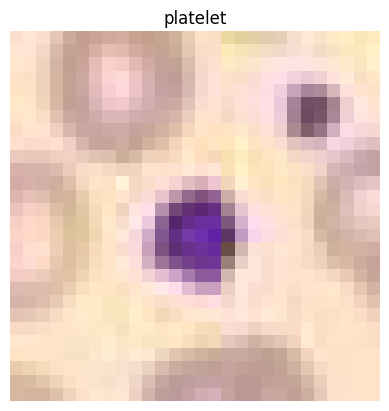

In [12]:
import matplotlib.pyplot as plt

class_names = INFO["bloodmnist"]["label"] #รวม mapping ที่ผูก numerics class id กับ ชื่อเม็ดเลือด

plt.imshow(image)
plt.title(class_names[str(label.item())])
plt.axis("off")
plt.show()

In [13]:

import numpy as np

# TODO: Convert the PIL image into a NumPy array

pil_image, label = train_dataset[1]
image = np.array(pil_image)

# TODO: Print shape, min, max, and dtype

print("Shape: ",image.shape)
print("Min: ",image.min())
print("Max", image.max())
print("dtype: ", image.dtype)

Shape:  (28, 28, 3)
Min:  25
Max 255
dtype:  uint8


In [14]:
class_names = INFO["bloodmnist"]["label"]

for class_id, class_name in class_names.items():
  print("class id: ",class_id, ", class name: ",class_name)

class id:  0 , class name:  basophil
class id:  1 , class name:  eosinophil
class id:  2 , class name:  erythroblast
class id:  3 , class name:  immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
class id:  4 , class name:  lymphocyte
class id:  5 , class name:  monocyte
class id:  6 , class name:  neutrophil
class id:  7 , class name:  platelet


In [15]:
labels = train_dataset.labels
print("Labels shape:", labels.shape)
print("First 10 labels: ",labels[:10])

flat_labels = labels.flatten() #แปลง array หลายมิติเป็น array 1 มิติ
class_counts = np.bincount(flat_labels) #นับจำนวนครั้งที่แต่ละ จำนวนเต็มที่ไม่ติดลบ แสดง

print("Class counts:", class_counts)
print("Total samples:", class_counts.sum())

Labels shape: (11959, 1)
First 10 labels:  [[7]
 [3]
 [6]
 [6]
 [7]
 [6]
 [2]
 [2]
 [7]
 [2]]
Class counts: [ 852 2181 1085 2026  849  993 2330 1643]
Total samples: 11959


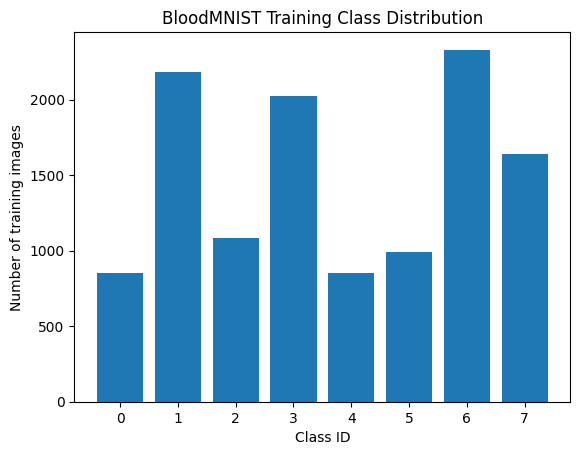

In [16]:
plt.bar(range(8), class_counts)
plt.xticks(range(8))
plt.xlabel("Class ID")
plt.ylabel("Number of training images")
plt.title("BloodMNIST Training Class Distribution")
plt.show()

In [17]:
#@title 3.1 Convert a PIL image to a tensor
# HWC uint8 [0,255] -> CHW float32 [0,1].
from torchvision import transforms

transform = transforms.ToTensor()
image, label = train_dataset[0]
image_tensor = transform(image)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("Min:", image_tensor.min().item())
print("Max:", image_tensor.max().item())

img = np.array(image)
print(image.getpixel((0, 0)))
print(img[0,0])
print(image_tensor[:,0,0])




Tensor shape: torch.Size([3, 28, 28])
Tensor dtype: torch.float32
Min: 0.12941177189350128
Max: 1.0
(250, 223, 206)
[250 223 206]
tensor([0.9804, 0.8745, 0.8078])


In [18]:
#@title 3.2 Prepare train, validation, and test datasets
# Train updates weights; validation guides choices; test is for final evaluation.
from medmnist import BloodMNIST
from torchvision import transforms

transform = transforms.ToTensor()

train_dataset = BloodMNIST(
    split="train",
    transform = transform,
    download = True
)

#create val dataset

val_dataset = BloodMNIST(
    split = "val",
    transform = transform,
    download = True
)


test_dataset = BloodMNIST(
    split = "test",
    transform = transform,
    download = True
)

print("Train:", len(train_dataset), "Validation:", len(val_dataset), "Test:", len(test_dataset))

image, label = train_dataset[0]
print(image.shape, image.dtype, label)

Train: 11959 Validation: 1712 Test: 3421
torch.Size([3, 28, 28]) torch.float32 [7]


In [19]:
#@title 3.3 Group images into batches
# Shuffle training data only.
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size = 32,
    shuffle = True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = 32,
    shuffle = False
)

test_loader = DataLoader(
    test_dataset,
    batch_size = 32,
    shuffle = False
)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels:", labels[:5])

Images shape: torch.Size([32, 3, 28, 28])
Labels shape: torch.Size([32, 1])
Images dtype: torch.float32
Labels: tensor([[6],
        [1],
        [7],
        [3],
        [1]])


In [20]:
#@title 3.4 Prepare integer labels for CrossEntropyLoss
# [B,1] -> [B]. Repeat for every new batch inside each loop.
print(labels.shape)
labels = labels.squeeze(1)
print(labels.shape, labels.dtype)

torch.Size([32, 1])
torch.Size([32]) torch.int64


## 4. Build the linear baseline

Start with a simple model to create a reference result before using a CNN.

1. Flatten each RGB image: `(3, 28, 28)` becomes 2,352 features. The batch dimension stays unchanged.
2. A Linear layer converts 2,352 values into 8 raw class scores (logits).
3. `argmax(dim=1)` selects the class with the largest score. These scores are not probabilities.
4. CrossEntropyLoss compares the raw scores with integer labels. Do not apply softmax first.
5. Clear gradients, calculate gradients with backward(), then update weights with the optimizer.
6. Repeat this process over all training batches for one epoch.

The one-batch and one-epoch cells below are learning demonstrations. The five-epoch section starts a fresh model for a clear baseline run.

In [21]:
import torch
from torch import nn
flatten = nn.Flatten()
#รวมทั้ง 3 dimensions(channel, hieght, width)เป็นมิติเดียว ด้วยการคูน
# ex) 3*28*28 = 2352
flat_images = flatten(images)
print("Before:", images.shape)
print("After: ",flat_images.shape)

# TODO 1: Create an nn.Linear layer named classifier
# Input features = 2352
# Output features = 8

classifier = nn.Linear(in_features=2352, out_features = 8)

# TODO 2: Pass flat_images through classifier
scores = classifier(flat_images)

# TODO 3: Print the shape of scores
print(scores.shape)


Before: torch.Size([32, 3, 28, 28])
After:  torch.Size([32, 2352])
torch.Size([32, 8])


In [22]:
model = nn.Sequential( #กำหนดว่าลำดับ ผ่าน layer ไหนบ้าง
    nn.Flatten(),
    classifier
)

scores = model(images)

In [23]:
scores = model(images)

print("Score shape: ",scores.shape)
print("First image scores: ",scores[0])
predictions = scores.argmax(dim=1)
print("Predictions: ",predictions[:5])
print("Actual Labels: ", labels[:5])

Score shape:  torch.Size([32, 8])
First image scores:  tensor([-0.2981, -0.1569,  0.1058, -0.3131,  0.1244,  0.9051, -0.1753,  0.0901],
       grad_fn=<SelectBackward0>)
Predictions:  tensor([5, 5, 5, 5, 5])
Actual Labels:  tensor([6, 1, 7, 3, 1])


In [24]:
criterion = nn.CrossEntropyLoss()
#measures the difference between model's prediction and correct labels

#1. calculate the loss
loss = criterion(scores, labels)

print("Loss: ",loss.item())


Loss:  2.2685227394104004


In [25]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(2352,8)
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr = 0.01
)

scores = model(images)
loss = criterion(scores,labels)

#update weights
optimizer.zero_grad()
loss.backward()
optimizer.step()

new_scores = model(images)
new_loss = criterion(new_scores, labels)

print("Before:", loss.item())
print("After:", new_loss.item())

Before: 1.9094411134719849
After: 1.7560454607009888


In [26]:
model.train()

total_loss=0

for images, labels in train_loader:
  labels = labels.squeeze(1)

  scores = model(images) #predict 8 score per image

  loss = criterion(scores, labels) #calculate prediction error

  optimizer.zero_grad() #clear old gradients
  loss.backward() #calculate new gradient
  optimizer.step() #update model weights

  total_loss+=loss.item()*images.size(0)

average_loss = total_loss / len(train_loader.dataset)

print("Training loss:", average_loss)

Training loss: 1.7495889012974455


## 5. Validate the baseline

Use the validation split to check performance on images that were not used for weight updates.

1. `model.eval()` selects evaluation behavior. This linear model has no Dropout or BatchNorm, so its layer behavior does not change.
2. `torch.no_grad()` avoids building a gradient graph.
3. Predict each validation batch and calculate loss.
4. Count correct predictions and divide by the number of validation images.

Validation does not update weights. Keep the test set for final evaluation after model choices are finished.

In [27]:
model.eval() #switch model to evaluation mode: disable dropout

total_val_loss = 0
correct = 0
total = 0

with torch.no_grad(): #no track gradient
  for images, labels in val_loader:
    labels = labels.squeeze(1)
    scores = model(images)
    loss = criterion(scores, labels)
    predictions = scores.argmax(dim = 1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    total_val_loss += loss.item() * images.size(0)

val_loss = total_val_loss / total
val_accuracy = correct / total

print("Validation loss:", val_loss)
print("Validation accuracy:", val_accuracy)

Validation loss: 1.2589182976250337
Validation accuracy: 0.530373831775701


## 6. Train and validate for five epochs

This is the main linear baseline experiment. Start a fresh model and optimizer, then repeat:

1. Train on every training batch and update weights.
2. Calculate average training loss, weighted by batch size.
3. Validate without updating weights.
4. Print training loss, validation loss, and validation accuracy.

An epoch is one full pass through the training dataset. Rerun this cell to start a new five-epoch experiment, rather than silently continuing earlier training. Results can vary between runs.

In [28]:
# Main baseline experiment: reset weights and optimizer before training.
model = nn.Sequential(nn.Flatten(), nn.Linear(2352, 8))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

num_epochs = 5

for epoch in range(num_epochs):
  model.train()
  total_loss = 0
  for images, labels in train_loader:
    labels = labels.squeeze(1)

    scores = model(images) #predict 8 score per image

    loss = criterion(scores, labels) #calculate prediction error

    optimizer.zero_grad() #clear old gradients
    loss.backward() #calculate new gradient
    optimizer.step() #update model weights
    total_loss+=loss.item()*images.size(0)

  average_loss = total_loss / len(train_loader.dataset)

  model.eval()
  total_val_loss = 0
  correct = 0
  total = 0
  with torch.no_grad(): #no track gradient
    for images, labels in val_loader:
      labels = labels.squeeze(1)
      scores = model(images)
      loss = criterion(scores, labels)
      predictions = scores.argmax(dim = 1)
      correct += (predictions == labels).sum().item()
      total += labels.size(0)

      total_val_loss += loss.item() * images.size(0)

  val_loss = total_val_loss / total
  val_accuracy = correct / total

  print(
          f"Epoch {epoch + 1}/{num_epochs} | "
          f"Train Loss: {average_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val Accuracy: {val_accuracy:.2%}"
  )

Epoch 1/5 | Train Loss: 1.7433 | Val Loss: 1.8200 | Val Accuracy: 43.40%
Epoch 2/5 | Train Loss: 1.3109 | Val Loss: 1.1749 | Val Accuracy: 53.62%
Epoch 3/5 | Train Loss: 1.1105 | Val Loss: 0.9487 | Val Accuracy: 63.90%
Epoch 4/5 | Train Loss: 1.0401 | Val Loss: 1.0277 | Val Accuracy: 58.12%
Epoch 5/5 | Train Loss: 0.9829 | Val Loss: 0.9566 | Val Accuracy: 64.84%


## 7. Explore CNN feature extraction (in progress)

A CNN keeps image structure while extracting patterns. This section inspects shapes; it does not train a CNN yet.

Process: RGB batch → convolution block 1 → convolution block 2 → flatten → classifier (next step).

The layers below start with random weights. Useful features are learned only when the complete model is trained.

### 7.1 Inspect convolution, ReLU, and pooling

Convolution produces 16 feature maps from 3 RGB channels. Padding 1 keeps the height and width unchanged for a 3×3 kernel. ReLU replaces negative values with zero. MaxPooling reduces 28×28 to 14×14.

The first cell shows each operation separately. The next combines them into one block: `(B, 3, 28, 28)` → `(B, 16, 14, 14)`. B means batch size. These layers are untrained; useful features will be learned during CNN training.

In [29]:
# Inspect a fresh batch and follow each CNN operation.
images, labels = next(iter(train_loader))

conv = nn.Conv2d(
    in_channels=3,
    out_channels=16,
    kernel_size=3,
    padding=1,
)
conv_output = conv(images)
print("Input:", images.shape)
print("After convolution:", conv_output.shape)

relu = nn.ReLU()  # Replace negative values with zero.
pool = nn.MaxPool2d(kernel_size=2)  # Keep the maximum in each 2x2 area.
activated = relu(conv_output)
pooled = pool(activated)
print("After ReLU:", activated.shape)
print("After pooling:", pooled.shape)

Input: torch.Size([32, 3, 28, 28])
After convolution: torch.Size([32, 16, 28, 28])
After ReLU: torch.Size([32, 16, 28, 28])
After pooling: torch.Size([32, 16, 14, 14])


In [30]:
#extract features
conv_block1 = nn.Sequential(
    nn.Conv2d(
      in_channels =3,
      out_channels = 16,
      kernel_size = 3,
      padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2)

)

images, labels = next(iter(train_loader))

output = conv_block1(images)
print(output.shape)

torch.Size([32, 16, 14, 14])


### 7.2 Add the second block and flatten

1. Receive the 16 feature maps from block 1.
2. Convolve them into 32 feature maps.
3. Apply ReLU and pooling, reducing 14×14 to 7×7.
4. Flatten each image to `32 × 7 × 7 = 1,568` features.

Shape flow: `(B, 16, 14, 14)` → `(B, 32, 7, 7)` → `(B, 1568)`. More feature maps means more channels; pooling reduces spatial size.

In [31]:
conv_block2 = nn.Sequential(
    nn.Conv2d(
        in_channels = 16,
        out_channels = 32,
        kernel_size = 3,
        padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2)
)

output2=conv_block2(output)
print("Block 1:", output.shape)
print("Block 2:", output2.shape)

flatten = nn.Flatten()
flat_output = flatten(output2)
print(flat_output.shape) #32*7*7=1568 features

Block 1: torch.Size([32, 16, 14, 14])
Block 2: torch.Size([32, 32, 7, 7])
torch.Size([32, 1568])


### 7.3 Next step: add the CNN classifier

**Not implemented yet.** Add a Linear layer from 1,568 features to 8 class scores. Then combine both convolution blocks, Flatten, and the classifier in one model.

After that: create a new optimizer for the CNN, train and validate it, compare it with the linear baseline, then evaluate the selected model on the test set and save its weights.

Current status: data exploration and linear baseline training are implemented. CNN feature extraction has been explored. A complete CNN, final test evaluation, and saved model are still pending.

In [32]:
classifier_cnn = nn.Linear(
    in_features = 1568,
    out_features= 8
)

cnn_scores = classifier_cnn(flat_output)

print("Flattened:", flat_output.shape)
print("CNN scores:", cnn_scores.shape)

Flattened: torch.Size([32, 1568])
CNN scores: torch.Size([32, 8])


In [33]:
cnn_model = nn.Sequential(
    nn.Conv2d(
      in_channels =3,
      out_channels = 16,
      kernel_size = 3,
      padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2),

    nn.Conv2d(
        in_channels = 16,
        out_channels = 32,
        kernel_size = 3,
        padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2),

    nn.Flatten(),

    nn.Linear(
        in_features = 1568,
        out_features = 8
    )
)

cnn_scores = cnn_model(images)

print("CNN output:", cnn_scores.shape)
print("CNN architecture:", cnn_model)

CNN output: torch.Size([32, 8])
CNN architecture: Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=8, bias=True)
)


In [34]:
criterion = nn.CrossEntropyLoss()

cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr = 0.001
)

In [35]:
num_epochs = 5
best_val_loss = float("inf")
best_epoch = 0
for epoch in range(num_epochs):
  cnn_model.train()
  total_loss = 0

  for images, labels in train_loader:
    labels = labels.squeeze(1)

    #forward pass using cnn model
    scores = cnn_model(images)
    loss = criterion(scores, labels)

    cnn_optimizer.zero_grad()
    loss.backward()
    cnn_optimizer.step()

    total_loss += loss.item() * images.size(0)

  train_loss = total_loss/len(train_loader.dataset)

  cnn_model.eval()
  total_val_loss = 0
  correct = 0
  total = 0

  with torch.no_grad(): #no track gradient
    for images, labels in val_loader:
      labels = labels.squeeze(1)
      scores = cnn_model(images)
      loss = criterion(scores, labels)
      predictions = scores.argmax(dim = 1)
      correct += (predictions == labels).sum().item()
      total += labels.size(0)

      total_val_loss += loss.item() * images.size(0)

  val_loss = total_val_loss / total
  val_accuracy = correct / total

  if(val_loss<best_val_loss):
    best_val_loss = val_loss
    best_epoch = epoch
    torch.save(cnn_model.state_dict(), "bloodmnist_cnn_best.pth")

  print(
      f"Epoch  {epoch+1}/{num_epochs} | "
      f"Train loss: {train_loss:.4f} | "
      f"Val loss: {val_loss:.4f} | "
      f"Val accuracy: {val_accuracy:.2%}"
      )



Epoch  1/5 | Train loss: 1.2128 | Val loss: 1.0893 | Val accuracy: 57.48%
Epoch  2/5 | Train loss: 0.8192 | Val loss: 0.7145 | Val accuracy: 74.36%
Epoch  3/5 | Train loss: 0.6620 | Val loss: 0.5658 | Val accuracy: 81.02%
Epoch  4/5 | Train loss: 0.5518 | Val loss: 0.5083 | Val accuracy: 82.77%
Epoch  5/5 | Train loss: 0.4893 | Val loss: 0.4545 | Val accuracy: 84.40%


In [36]:
weights = cnn_model.state_dict()
#return dictionary of the model's parameter including convolutional filter

print(type(weights))
print(list(weights.keys()))

for name, parameter in cnn_model.state_dict().items():
    print(name, parameter.shape)

<class 'collections.OrderedDict'>
['0.weight', '0.bias', '3.weight', '3.bias', '7.weight', '7.bias']
0.weight torch.Size([16, 3, 3, 3])
0.bias torch.Size([16])
3.weight torch.Size([32, 16, 3, 3])
3.bias torch.Size([32])
7.weight torch.Size([8, 1568])
7.bias torch.Size([8])


In [37]:

#for Reuse trained weights without training again
import torch
checkpoint_path = "bloodmnist_cnn_latest.pth"

torch.save( #serialize tensor
  cnn_model.state_dict(),
  checkpoint_path
)

print("saved", checkpoint_path)

import os
print("file exist", os.path.exists(checkpoint_path))
print("file_size", os.path.getsize(checkpoint_path))

saved bloodmnist_cnn_latest.pth
file exist True
file_size 73789


In [38]:
torch.manual_seed(42)

cnn_model = (
    nn.Sequential(
        nn.Conv2d(
            in_channels = 3,
            out_channels = 16,
            kernel_size = 3,
            padding = 1
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2),

        nn.Conv2d(
            in_channels = 16,
            out_channels = 32,
            kernel_size = 3,
            padding = 1
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2),

        nn.Flatten(),

        nn.Linear(
            in_features = 1568,
            out_features = 8
        )
    )
)
cnn_scores = cnn_model(images)


cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

num_epochs = 5
best_val_loss = float("inf")
best_epoch = 0
for epoch in range(num_epochs):
  cnn_model.train()
  total_loss = 0

  for images, labels in train_loader:
    labels = labels.squeeze(1)

    #forward pass using cnn model
    scores = cnn_model(images)
    loss = criterion(scores, labels)

    cnn_optimizer.zero_grad()
    loss.backward()
    cnn_optimizer.step()

    total_loss += loss.item() * images.size(0)

  train_loss = total_loss/len(train_loader.dataset)

  cnn_model.eval()
  total_val_loss = 0
  correct = 0
  total = 0

  with torch.no_grad(): #no track gradient
    for images, labels in val_loader:
      labels = labels.squeeze(1)
      scores = cnn_model(images)
      loss = criterion(scores, labels)
      predictions = scores.argmax(dim = 1)
      correct += (predictions == labels).sum().item()
      total += labels.size(0)

      total_val_loss += loss.item() * images.size(0)

  val_loss = total_val_loss / total
  val_accuracy = correct / total

  if(val_loss<best_val_loss):
    best_val_loss = val_loss
    best_epoch = epoch
    torch.save(cnn_model.state_dict(), "bloodmnist_cnn_best.pth")

  print(
      f"Epoch  {epoch+1}/{num_epochs} | "
      f"Train loss: {train_loss:.4f} | "
      f"Val loss: {val_loss:.4f} | "
      f"Val accuracy: {val_accuracy:.2%}"
      )

Epoch  1/5 | Train loss: 1.1288 | Val loss: 0.8480 | Val accuracy: 70.91%
Epoch  2/5 | Train loss: 0.7183 | Val loss: 0.6037 | Val accuracy: 78.45%
Epoch  3/5 | Train loss: 0.5811 | Val loss: 0.5188 | Val accuracy: 81.25%
Epoch  4/5 | Train loss: 0.5002 | Val loss: 0.5159 | Val accuracy: 82.01%
Epoch  5/5 | Train loss: 0.4633 | Val loss: 0.4173 | Val accuracy: 86.16%


In [39]:
import os

checkpoint_path = "bloodmnist_cnn_best.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Best validation loss:", best_val_loss)
print("Best epoch:", best_epoch + 1)

Checkpoint exists: True
Best validation loss: 0.417279367970529
Best epoch: 5


In [40]:
loaded_model = nn.Sequential(
    nn.Conv2d(
        in_channels = 3,
        out_channels = 16,
        kernel_size = 3,
        padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2),
    nn.Conv2d(
        in_channels = 16,
        out_channels = 32,
        kernel_size = 3,
        padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2),
    nn.Flatten(),
    nn.Linear(
        in_features = 1568,
        out_features = 8
    )
)

saved_weights = torch.load(
    "bloodmnist_cnn_best.pth",
    map_location="cpu",
    weights_only=True
)

loaded_model.load_state_dict(saved_weights)
loaded_model.eval()

images, labels = next(iter(val_loader))

cnn_model.eval()
loaded_model.eval()

with torch.no_grad():
    original_scores = cnn_model(images)
    loaded_scores = loaded_model(images)

print(
    "Same outputs:",
    torch.allclose(original_scores, loaded_scores)
)

loaded_model.eval()

correct = 0
total = 0
total_val_loss = 0

with torch.no_grad():
    for images, labels in val_loader:
        labels = labels.squeeze(1)

        # TODO 1: Predict using loaded_model
        scores = loaded_model(images)

        # TODO 2: Calculate loss
        loss = criterion(scores, labels)

        # TODO 3: Get predicted class IDs
        predictions =  scores.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        total_val_loss += loss.item() * images.size(0)

loaded_val_loss = total_val_loss / total
loaded_val_accuracy = correct / total

print("Loaded validation loss:", loaded_val_loss)
print("Loaded validation accuracy:", f"{loaded_val_accuracy:.2%}")

Same outputs: True
Loaded validation loss: 0.417279367970529
Loaded validation accuracy: 86.16%


In [41]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = loaded_model.to(device) #Moves model parameters to CPU or GPU

model.eval()

y_true=[]
y_pred=[]

with torch.no_grad():
  for images, labels in val_loader:
    images = images.to(device) #move images to the same cpu / g[u as cnn]
    outputs = model(images)

    predictions = outputs.argmax(dim=1) #select index with highest score
    y_true.extend(labels.view(-1).cpu().tolist())
    y_pred.extend(predictions.cpu().tolist()) #converts prediction tensors into python list

print("Actual labels:", len(y_true))
print("Predictions:", len(y_pred))

correct = sum(true == pred for true, pred in zip(y_true, y_pred))
accuracy = correct / len(y_true)
print(correct)
print(f"Validation accuracy: {accuracy:.2%}")

Actual labels: 1712
Predictions: 1712
1475
Validation accuracy: 86.16%


per - class performance

In [42]:
from sklearn.metrics import classification_report
report = classification_report(
    y_true = y_true,
    y_pred = y_pred,
    digits = 4
)

print(report)


from sklearn.metrics import confusion_matrix

# TODO 1: Generate the confusion matrix
cm = confusion_matrix(
    y_true = y_true,
    y_pred = y_pred,
    labels=list(range(8))
)

print(cm)
print("Matrix shape:", cm.shape)


              precision    recall  f1-score   support

           0     0.7183    0.8361    0.7727       122
           1     0.9645    0.9583    0.9614       312
           2     0.7419    0.8903    0.8094       155
           3     0.7351    0.6793    0.7061       290
           4     0.8900    0.7295    0.8018       122
           5     0.7591    0.7273    0.7429       143
           6     0.9436    0.9550    0.9493       333
           7     0.9828    0.9702    0.9764       235

    accuracy                         0.8616      1712
   macro avg     0.8419    0.8432    0.8400      1712
weighted avg     0.8639    0.8616    0.8610      1712

[[102   1   1  10   4   4   0   0]
 [  4 299   1   3   1   1   3   0]
 [  1   0 138  10   1   0   1   4]
 [ 22   7  22 197   5  24  13   0]
 [  8   0  10  15  89   0   0   0]
 [  5   2   4  26   0 104   2   0]
 [  0   1   3   7   0   4 318   0]
 [  0   0   7   0   0   0   0 228]]
Matrix shape: (8, 8)


In [43]:

checkpoint = torch.load(
    "bloodmnist_cnn_best.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))


Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['0.weight', '0.bias', '3.weight', '3.bias', '7.weight', '7.bias']


In [44]:
print(loaded_model)

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=8, bias=True)
)


In [45]:
import shutil
from pathlib import Path

source = Path("bloodmnist_cnn_best.pth")
backup = Path("bloodmnist_cnn_backup.pth")
assert source.exists(), "check point not found"
assert not backup.exists(), "backup already exist"

shutil.copy2(source,backup)

print("Backup created:", backup.exists())
print("Backup size:", backup.stat().st_size)


Backup created: True
Backup size: 73765


day 6 10 epoch experiment

In [46]:
torch.manual_seed(42)

cnn_model_10 = nn.Sequential(
    nn.Conv2d(
        in_channels = 3,
        out_channels = 16,
        kernel_size = 3,
        padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2),
    nn.Conv2d(
        in_channels = 16,
        out_channels = 32,
        kernel_size = 3,
        padding = 1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size = 2),
    nn.Flatten(),
    nn.Linear(
        in_features = 1568,
        out_features = 8
    )
)

cnn_optimizer_10 = torch.optim.Adam(
    cnn_model_10.parameters(),
    lr=0.001
)

num_epochs_10 = 10
best_val_loss_10 = float("inf")
best_epoch_10 = 0

images, labels = next(iter(val_loader))

with torch.no_grad():
    scores = cnn_model_10(images)

print("Output shape:", scores.shape)

Output shape: torch.Size([32, 8])


In [47]:
num_epochs_10 = 10

for epoch in range(num_epochs_10):
  cnn_model_10.train()
  total_loss = 0

  for images, labels in train_loader:
    labels = labels.squeeze(1)

    scores = cnn_model_10(images)

    loss = criterion(scores, labels)

    cnn_optimizer_10.zero_grad()
    loss.backward()
    cnn_optimizer_10.step()

    total_loss += loss.item() * images.size(0)

  train_loss = total_loss / len(train_loader.dataset)

  cnn_model_10.eval()
  total_val_loss = 0
  correct = 0
  total = 0

  with torch.no_grad():
    for images, labels in val_loader:
      labels = labels.squeeze(1)
      scores = cnn_model_10(images)

      loss=criterion(scores, labels)

      predictions = scores.argmax(dim=1)
      correct += (predictions == labels).sum().item()
      total+=labels.size(0)
      total_val_loss += loss.item() * images.size(0)

    val_loss = total_val_loss / total
    val_accuracy = correct / total

    # TODO 6: Save the model when validation loss improves
    if val_loss<best_val_loss_10:
        best_val_loss_10 = val_loss
        best_epoch_10 = epoch + 1
        torch.save(
            cnn_model_10.state_dict(),
            "bloodmnist_cnn_10epochs.pth"
        )

    print(
        f"Epoch {epoch+1}/{num_epochs_10} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.2%}"
    )

Epoch 1/10 | Train loss: 1.1521 | Val loss: 0.8319 | Val accuracy: 72.66%
Epoch 2/10 | Train loss: 0.7374 | Val loss: 0.6622 | Val accuracy: 75.82%
Epoch 3/10 | Train loss: 0.5806 | Val loss: 0.5242 | Val accuracy: 82.18%
Epoch 4/10 | Train loss: 0.5031 | Val loss: 0.4769 | Val accuracy: 81.78%
Epoch 5/10 | Train loss: 0.4565 | Val loss: 0.4301 | Val accuracy: 84.29%
Epoch 6/10 | Train loss: 0.4150 | Val loss: 0.3728 | Val accuracy: 87.03%
Epoch 7/10 | Train loss: 0.3946 | Val loss: 0.3811 | Val accuracy: 86.51%
Epoch 8/10 | Train loss: 0.3689 | Val loss: 0.3409 | Val accuracy: 88.49%
Epoch 9/10 | Train loss: 0.3404 | Val loss: 0.3277 | Val accuracy: 89.19%
Epoch 10/10 | Train loss: 0.3238 | Val loss: 0.3365 | Val accuracy: 87.56%


In [48]:
import copy
verified_model_10 = copy.deepcopy(cnn_model_10)

verified_model_10.load_state_dict(
    torch.load(
        "bloodmnist_cnn_10epochs.pth",
        map_location = "cpu",
        weights_only = True
    )
)

verified_model_10.eval()

y_true_10 = []
y_pred_10 = []

with torch.no_grad():
  for images, labels in val_loader:
    scores = verified_model_10(images)

    predictions = scores.argmax(dim=1) #select index with highest score
    y_true_10.extend(labels.view(-1).cpu().tolist())
    y_pred_10.extend(predictions.cpu().tolist()) #converts prediction tensors into python list

correct_10 = sum(
    true == pred
    for true, pred in zip(y_true_10, y_pred_10)
)

accuracy_10 = correct_10 / len(y_true_10)
print("Validation images:", len(y_true_10))
print(f"Reloaded checkpoint accuracy: {accuracy_10:.2%}")
print("Saved best epoch:", best_epoch_10)

Validation images: 1712
Reloaded checkpoint accuracy: 89.19%
Saved best epoch: 9


In [49]:
from sklearn.metrics import classification_report

report_10 = classification_report(
    y_true = y_true_10,
    y_pred = y_pred_10,
    digits = 4
)

print(report_10)

              precision    recall  f1-score   support

           0     0.8947    0.6967    0.7834       122
           1     0.9837    0.9679    0.9758       312
           2     0.9079    0.8903    0.8990       155
           3     0.7242    0.8241    0.7710       290
           4     0.7532    0.9508    0.8406       122
           5     0.8430    0.7133    0.7727       143
           6     0.9811    0.9339    0.9569       333
           7     0.9915    0.9957    0.9936       235

    accuracy                         0.8919      1712
   macro avg     0.8849    0.8716    0.8741      1712
weighted avg     0.8989    0.8919    0.8926      1712



In [50]:
from pathlib import Path
import hashlib

checkpoint_path = Path("bloodmnist_cnn_10epochs.pth")

assert  checkpoint_path.exists(),"checkpoint not found"

checkpoint_hash = hashlib.sha256(
    checkpoint_path.read_bytes()
).hexdigest()


print("Selected checkpoint:", checkpoint_path.name)
print("SHA256:", checkpoint_hash)
#sha26 create a finger print of the exact checkpoint file, if the weight change sha change
print("Size:", checkpoint_path.stat().st_size, "bytes")

Selected checkpoint: bloodmnist_cnn_10epochs.pth
SHA256: 2b1b021cfc623940f2bf531aedb00d5951f29e482918e7a53a03071f6d0251db
Size: 73877 bytes


In [51]:
from medmnist import BloodMNIST
from torch.utils.data import DataLoader

test_dataset = BloodMNIST(
    split = "test", #load official test image
    transform = val_dataset.transform, #apply the same preprocessing as validation
    download = True
)

test_loader = DataLoader(
    test_dataset,
    batch_size = 32,
    shuffle = False
)


print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

test_model = verified_model_10

test_model.load_state_dict(
    torch.load(
        "bloodmnist_cnn_10epochs.pth",
        map_location = "cpu",
        weights_only = True
    )
)

test_model.eval()

total_test_loss = 0
correct = 0
total = 0

y_true_test = []
y_pred_test = []

with torch.no_grad():
  for images, labels in test_loader:
    labels = labels.squeeze(1)

    scores = test_model(images)

    loss = criterion(scores, labels)

    predictions = scores.argmax(dim=1)

    correct+= (predictions==labels).sum().item()

    total += labels.size(0) #number of image in that batch (32 images)
    total_test_loss += loss.item()*images.size(0)


    y_true_test.extend(labels.view(-1).cpu().tolist())
    y_pred_test.extend(predictions.cpu().tolist())

test_loss = total_test_loss / total
test_accuracy = correct / total

print("Correct predictions:", correct)
print("Test images evaluated:", total)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test images: 3421
Test batches: 107
Correct predictions: 3009
Test images evaluated: 3421
Test loss: 0.3491
Test accuracy: 87.96%


In [52]:
from sklearn.metrics import classification_report, confusion_matrix

test_report = classification_report(
    y_true = y_true_test,
    y_pred = y_pred_test,
    digits = 4
)

mat = confusion_matrix(
    y_true = y_true_test,
    y_pred = y_pred_test,
    labels = list(range(8))
)

print(test_report)
print(mat)

              precision    recall  f1-score   support

           0     0.8398    0.7090    0.7689       244
           1     0.9707    0.9567    0.9637       624
           2     0.9186    0.8714    0.8944       311
           3     0.6897    0.8290    0.7529       579
           4     0.7942    0.9053    0.8462       243
           5     0.8147    0.6655    0.7326       284
           6     0.9714    0.9174    0.9436       666
           7     0.9936    0.9957    0.9947       470

    accuracy                         0.8796      3421
   macro avg     0.8741    0.8563    0.8621      3421
weighted avg     0.8869    0.8796    0.8806      3421

[[173   1   0  48  12   9   1   0]
 [  6 597   0  13   3   3   2   0]
 [  1   1 271  20   9   0   6   3]
 [ 21  11  12 480  20  28   7   0]
 [  0   0   3  18 220   2   0   0]
 [  5   0   2  82   4 189   2   0]
 [  0   5   5  35   9   1 611   0]
 [  0   0   2   0   0   0   0 468]]


In [53]:
from pathlib import Path
import json
from sklearn.metrics import classification_report

results = {
    "checkpoint":"bloodmnist_cnn_10epochs.pth",
    "checkpoint_sha256":"8884f42fa148ab57a5ed9d11c15cbf6998c1394171048708041d737211a74f6d",
    "dataset":"BloodMNIST",
    "split":"test",
    "num_samples":len(y_true_test),
    "test_loss":test_loss,
    "test_accuracy": test_accuracy,
    "classification_report":classification_report(
        y_true_test,
        y_pred_test,
        output_dict = True, #make it in dictionary format
        zero_division = 0
    ),
    "confusion_matrix": mat.tolist()

}

output_path = Path("bloodmnist_test_results.json")

with output_path.open("w") as f:
    json.dump(results, f, indent=2)

print("Results saved:", output_path.exists())

with output_path.open("r") as f:
    saved_results = json.load(f)

print("Test samples:", saved_results["num_samples"])
print(f"Test accuracy: {saved_results['test_accuracy']:.2%}")

Results saved: True
Test samples: 3421
Test accuracy: 87.96%


In [58]:
def predicted_image(model, image_tensor, class_mapping):
  model.eval()

  device = next(model.parameters()).device
  #find which device so the function can work on both cpu gpu


  with torch.no_grad():
    image_batch = image_tensor.unsqueeze(0).to(device)
    #turn (3, 28, 28) → (1, 3, 28, 28) so cnn can process

    scores = model(image_batch)
    predicted_class = scores.argmax(dim = 1).item()

  class_id = str(predicted_class)

  class_name = class_mapping[str(predicted_class)]

  return {
        "class_id": predicted_class,
        "class_name": class_name
    }


image, actual_label = test_dataset[0]

result = predicted_image(
    test_model,
    image,
    blood_info["label"]
)

print(result)

{'class_id': 3, 'class_name': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)'}


In [57]:
from medmnist import INFO

blood_info = INFO["bloodmnist"]

print("Number of classes:", len(blood_info["label"]))
print("Class mapping:", blood_info["label"])

Number of classes: 8
Class mapping: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}


###create reusable function

for outside colab

another Python script can
- recreate your CNN
- load its trained weights without running the training notebook.



---



File	Purpose

model.py
- Defines the CNN architecture

bloodmnist_cnn_10epochs.pth
- Contains trained model weights

model_config.json
- Describes image input, preprocessing, and class names

In [59]:
%%writefile model.py
import torch.nn as nn

def create_cnn():
  model = nn.Sequential(
      nn.Conv2d(
          in_channels = 3,
          out_channels = 16,
          kernel_size = 3,
          padding = 1
      ),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size = 2),

      nn.Conv2d(
          in_channels = 16,
          out_channels = 32,
          kernel_size = 3,
          padding = 1
      ),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size = 2),
      nn.Flatten(),
      nn.Linear(
          in_features = 1568,
          out_features = 8
      )

  )
  return model

Writing model.py


In [60]:
from model import create_cnn
new_model = create_cnn()

print(new_model)

new_model.load_state_dict(
    torch.load(
        "bloodmnist_cnn_10epochs.pth",
        map_location="cpu",
        weights_only=True
    )
)

print("Checkpoint loaded successfully!")

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=8, bias=True)
)
Checkpoint loaded successfully!


In [68]:
%%writefile inference.py

import torch
def predicted_image(model, image_tensor, class_mapping):
  model.eval()
  device = next(model.parameters()).device

  with torch.no_grad():
    image_batch = image_tensor.unsqueeze(0).to(device)
    # add batch dimension and move image to device

    #run the model and select the class id
    scores = model(image_batch)
    predicted_class = scores.argmax(dim = 1).item()

  #convert class id to string and to class_name
  class_id = str(predicted_class)
  class_name = class_mapping[str(predicted_class)]

  return{
      "class_id" : predicted_class,
      "class_name" : class_name
  }

Overwriting inference.py


In [69]:
from inference import predicted_image
new_model.eval()

image, actual_label = test_dataset[0]

result = predicted_image(
    new_model,
    image,
    blood_info["label"]
)

print(result)

{'class_id': 3, 'class_name': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)'}


In [66]:
import importlib
import inference

importlib.reload(inference)
predicted_image = inference.predicted_image

In [70]:
print("Image shape:", image.shape)
print("Actual class:", blood_info["label"][str(actual_label.item())])
print("Prediction:", result)

Image shape: torch.Size([3, 28, 28])
Actual class: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
Prediction: {'class_id': 3, 'class_name': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)'}


In [75]:
import json
from pathlib import Path

model_config = {
    "model_name":"bloodmnist_cnn",
    "dataset":"BloodMNIST",
    "input_shape":[3,28,28],
    "num_classes":8,
    "preprocessing": "ToTensor",
    "class_mapping": blood_info["label"],
    "checkpoint":"bloodmnist_cnn_10epochs.pth"
}

output_path = Path("model_config.json") #สร้างตำแหน่งไฟล์ model_config.json

with output_path.open("w") as f: #open file in mode write
#with = ปิดไฟล์อัตโนมัติเมื่อทำเสด,
#open("w") เปิดไฟล์ในโหมดเขียน (write)
    json.dump(model_config, f, indent=2)

print("config saved:", Path("model_config.json").exists())

config saved: True


In [76]:

with open("model_config.json", "r") as f:
    loaded_config = json.load(f)

print("Model:", loaded_config["model_name"])
print("Classes:", loaded_config["num_classes"])
print("Preprocessing:", loaded_config["preprocessing"])
print("Class 5:", loaded_config["class_mapping"]["5"])


Model: bloodmnist_cnn
Classes: 8
Preprocessing: ToTensor
Class 5: monocyte


In [81]:
from google.colab import files

files.download("model_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [82]:

from pathlib import Path
import zipfile

project_files = [
    "model.py",
    "inference.py",
    "model_config.json",
    "bloodmnist_cnn_10epochs.pth",
    "bloodmnist_test_results.json"
]

# Check that all required files exist
for filename in project_files:
    assert Path(filename).exists(), f"Missing: {filename}"

# Package the files
with zipfile.ZipFile("bloodmnist_phase1.zip", "w") as archive:
    for filename in project_files:
        archive.write(filename)

print("Archive created:", Path("bloodmnist_phase1.zip").exists())
print("Files included:", project_files)


Archive created: True
Files included: ['model.py', 'inference.py', 'model_config.json', 'bloodmnist_cnn_10epochs.pth', 'bloodmnist_test_results.json']


In [83]:
from google.colab import files

files.download("bloodmnist_phase1.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [87]:

%%writefile requirements.txt
torch==2.11.0
torchvision==0.26.0
medmnist==3.0.2
scikit-learn==1.6.1
numpy==2.1.3
Pillow==11.3.0


Overwriting requirements.txt


In [85]:
from pathlib import Path

requirements_path = Path("requirements.txt")

print("File exists:", requirements_path.exists())
print(requirements_path.read_text())

File exists: True
torch
torchvision
medmnist
scikit-learn
numpy
Pillow



In [86]:

from importlib.metadata import version

packages = [
    "torch",
    "torchvision",
    "medmnist",
    "scikit-learn",
    "numpy",
    "Pillow"
]

for package in packages:
    print(f"{package}=={version(package)}")


torch==2.11.0+cpu
torchvision==0.26.0+cpu
medmnist==3.0.2
scikit-learn==1.6.1
numpy==2.1.3
Pillow==11.3.0


In [88]:
from pathlib import Path

print(Path("requirements.txt").read_text())

torch==2.11.0
torchvision==0.26.0
medmnist==3.0.2
scikit-learn==1.6.1
numpy==2.1.3
Pillow==11.3.0



In [91]:
%%writefile verify_inference.py

import json
import torch
from torchvision import transforms
from medmnist import BloodMNIST

from model import create_cnn
from inference import predicted_image

#1. load model config
with open("model_config.json","r") as f:
  config = json.load(f)

#2. create cnn architecture
model = create_cnn()

#3.load the trained checkpoint
model.load_state_dict(
    torch.load(
        config["checkpoint"],
        map_location="cpu",
        weights_only = True
    )
)

#4.load one sample  using the recorded preprocessing
assert config["preprocessing"] == "ToTensor"

dataset = BloodMNIST(
    split = "test",
    transform = transforms.ToTensor(),
    download = True
)

image, actual_label = dataset[0]

#5. predict class using imported inference function

result = predicted_image(model, image, config["class_mapping"])

print("Actual class:", config["class_mapping"][str(actual_label.item())])
print("Prediction:", result)

Overwriting verify_inference.py


In [92]:
!python verify_inference.py

Actual class: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
Prediction: {'class_id': 3, 'class_name': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)'}


In [93]:
from pathlib import Path

files_to_check = [
    "model.py",
    "inference.py",
    "verify_inference.py",
    "model_config.json",
    "requirements.txt",
    "bloodmnist_cnn_10epochs.pth",
    "bloodmnist_test_results.json"
]

for filename in files_to_check:
    path = Path(filename)
    print(f"{filename}: {'FOUND' if path.is_file() else 'MISSING'}")

model.py: FOUND
inference.py: FOUND
verify_inference.py: FOUND
model_config.json: FOUND
requirements.txt: FOUND
bloodmnist_cnn_10epochs.pth: FOUND
bloodmnist_test_results.json: FOUND


In [96]:
from pathlib import Path

import shutil
project = Path("bloodcell-ml-platform")

(project / "models").mkdir(parents=True, exist_ok=True)
(project / "results").mkdir(parents=True, exist_ok=True)
(project / "notebooks").mkdir(parents=True, exist_ok=True)

source_files = [
    "model.py",
    "inference.py",
    "verify_inference.py",
    "model_config.json",
    "requirements.txt"
]

for filename in source_files:
  shutil.copy2(filename, project / filename)


#copy trained models and evaluation results
shutil.copy2(
    "bloodmnist_cnn_10epochs.pth",
    project / "models" / "bloodmnist_cnn_10epochs.pth"
)

shutil.copy2(
    "bloodmnist_test_results.json",
    project / "results" / "bloodmnist_test_results.json"
)

print("Project files:")

for path in sorted(project.rglob("*")):
  if path.is_file():
    print(path)

Project files:
bloodcell-ml-platform/inference.py
bloodcell-ml-platform/model.py
bloodcell-ml-platform/model_config.json
bloodcell-ml-platform/models/bloodmnist_cnn_10epochs.pth
bloodcell-ml-platform/requirements.txt
bloodcell-ml-platform/results/bloodmnist_test_results.json
bloodcell-ml-platform/verify_inference.py


In [97]:

from pathlib import Path
import json

project = Path("bloodcell-ml-platform")
config_path = project / "model_config.json"

with config_path.open("r") as f:
    config = json.load(f)

# Update checkpoint path relative to project root
config["checkpoint"] = "models/bloodmnist_cnn_10epochs.pth"

with config_path.open("w") as f:
    json.dump(config, f, indent=2)

print("Checkpoint path:", config["checkpoint"])
print("Checkpoint exists:", (project / config["checkpoint"]).exists())


Checkpoint path: models/bloodmnist_cnn_10epochs.pth
Checkpoint exists: True


In [99]:
!cd bloodcell-ml-platform && python verify_inference.py

Actual class: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
Prediction: {'class_id': 3, 'class_name': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)'}
